# Formative 2 · Task 2: Image Data Collection and Processing

**Multimodal Data Preprocessing: User Identity and Product Recommendation System**

This notebook prepares the **face** part of the system. A user must pass the face check before the product model may run:

![System flow](docs/system_flow.png)

What this notebook does, in order:

| Step | Section | Output |
|---|---|---|
| 1 | Load and check the photos (3 expressions per member) | inventory table, photo grid |
| 2 | Detect and align each face | detections figure, 112×112 aligned crops |
| 3 | Augment every photo 6 ways (rotation, flip, grayscale, low light, blur, noise) | `images/augmented/` |
| 4 | Extract features: 128-d face embedding, colour and texture histograms | `features/image_features.csv` |
| 5 | Check the features can tell members apart | similarity heatmap, PCA plot, nearest-neighbour check |

The same face steps are also saved in `src/image_features.py`, so the command-line app can process a new face at login exactly like the training photos.

## 0. Setup

In [1]:
import os
import urllib.request

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from skimage.feature import local_binary_pattern
from sklearn.decomposition import PCA

# photos make big PNGs, so show the figures as JPEG to keep the notebook small
%config InlineBackend.figure_format = "jpeg"

MEMBERS = ["ketia", "twariq", "audric"]
EXPRESSIONS = ["neutral", "smiling", "surprised"]
AUGMENTATIONS = ["rotate_15", "flip_horizontal", "grayscale", "low_light", "gaussian_blur", "gaussian_noise"]

for folder in ["images/augmented", "images/faces", "features", "figures", "models"]:
    os.makedirs(folder, exist_ok=True)

## 1. Load and check the photos

Each member submitted three photos: **neutral**, **smiling** and **surprised**. They are stored in `images/raw/` with one naming rule, `<member>_<expression>.jpg`, so every later file name and every CSV row can be traced back to its source photo.

The photos come from different phones and places (outdoors by a lake, outside on grass, indoors against plain walls), so resolution, lighting and background all vary. That variety is useful: the face check must work in whatever conditions a user logs in from.

In [2]:
rows = []
for member in MEMBERS:
    for expression in EXPRESSIONS:
        path = f"images/raw/{member}_{expression}.jpg"
        img = cv2.imread(path)
        rows.append({"member": member, "expression": expression, "file": path,
                     "width": img.shape[1], "height": img.shape[0],
                     "size_kb": round(os.path.getsize(path) / 1024)})

inventory = pd.DataFrame(rows)
print(len(inventory), "photos,", inventory["member"].nunique(), "members")
inventory

9 photos, 3 members


,member,expression,file,width,height,size_kb
0,ketia,neutral,images/raw/ketia_neutral.jpg,607,1080,88
1,ketia,smiling,images/raw/ketia_smiling.jpg,810,1080,73
2,ketia,surprised,images/raw/ketia_surprised.jpg,719,1280,90
3,twariq,neutral,images/raw/twariq_neutral.jpg,720,1280,50
4,twariq,smiling,images/raw/twariq_smiling.jpg,720,1280,50
5,twariq,surprised,images/raw/twariq_surprised.jpg,899,1429,229
6,audric,neutral,images/raw/audric_neutral.jpg,960,1280,73
7,audric,smiling,images/raw/audric_smiling.jpg,960,1280,69
8,audric,surprised,images/raw/audric_surprised.jpg,960,1280,36


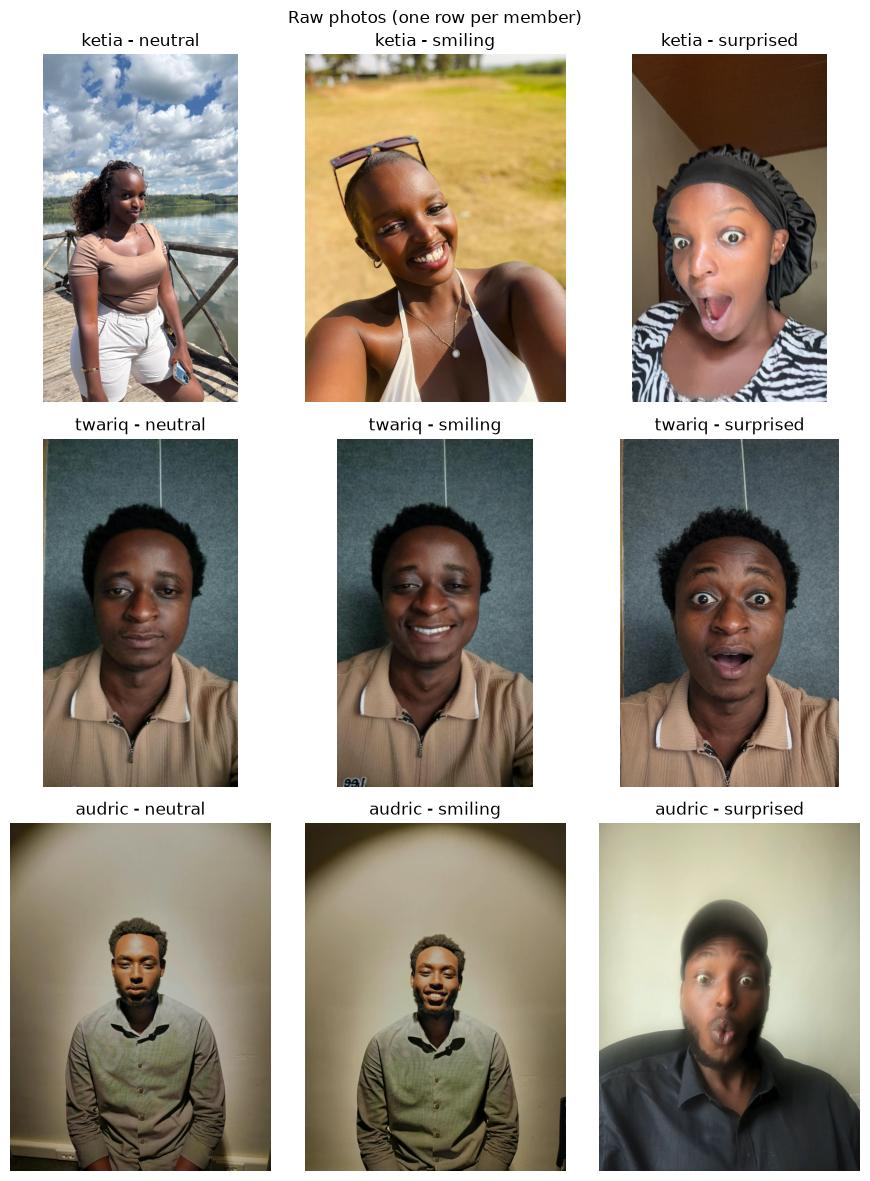

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(9, 12))
for i, member in enumerate(MEMBERS):
    for j, expression in enumerate(EXPRESSIONS):
        img = cv2.imread(f"images/raw/{member}_{expression}.jpg")
        axes[i, j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i, j].set_title(f"{member} - {expression}")
        axes[i, j].axis("off")
plt.suptitle("Raw photos (one row per member)")
plt.tight_layout()
plt.savefig("figures/task2_01_raw_photos.png", dpi=80)
plt.show()

## 2. Face pipeline: detect → align → describe

The raw photos are mostly background (water, walls, furniture). A model trained on whole photos would learn *where* a photo was taken, not *who* is in it. So every photo goes through the same three steps:

1. **Resize** so the longest side is 800 px. The 12-megapixel photos shrink, the small ones stay as they are.
2. **Detect** the face with **YuNet**, OpenCV's lightweight CNN face detector. It returns a box, five landmarks (eyes, nose tip, mouth corners) and a confidence score.
3. **Align** the face: the five landmarks are used to rotate and scale it into a 112×112 crop with the eyes level, so a tilted head and an upright one line up.
4. **Describe** the aligned crop with four groups of features:

| Feature group | Columns | What it captures |
|---|---|---|
| **SFace embedding** | `emb_000`–`emb_127` | 128 numbers from a pretrained face-recognition CNN, scaled to length 1. Two photos of the same person point in a similar direction, so cosine similarity measures identity. |
| **HSV colour histogram** | `hsv_h_*`, `hsv_s_*`, `hsv_v_*` (8 bins each) | skin tone, colour cast and lighting |
| **LBP texture histogram** | `lbp_0`–`lbp_9` | local texture (edges, spots, flat skin) from uniform Local Binary Patterns, P=8, R=1 |
| **Brightness / contrast** | `brightness`, `contrast` | mean and spread of grey levels, 0–1 |

The two cells below load the pretrained models and define these steps as functions.

In [4]:
# pretrained models from the OpenCV model zoo, downloaded once
YUNET = "models/face_detection_yunet_2023mar.onnx"
SFACE = "models/face_recognition_sface_2021dec.onnx"
ZOO = "https://github.com/opencv/opencv_zoo/raw/main/models/"

if not os.path.exists(YUNET):
    urllib.request.urlretrieve(ZOO + "face_detection_yunet/face_detection_yunet_2023mar.onnx", YUNET)
if not os.path.exists(SFACE):
    urllib.request.urlretrieve(ZOO + "face_recognition_sface/face_recognition_sface_2021dec.onnx", SFACE)

detector = cv2.FaceDetectorYN.create(YUNET, "", (320, 320), 0.6, 0.3, 5000)
recognizer = cv2.FaceRecognizerSF.create(SFACE, "")

In [5]:
def load_image(path, max_side=800):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        img = cv2.resize(img, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    return img


def detect_face(img):
    # returns the most confident face: x, y, w, h, 5 landmark points, score (or None)
    h, w = img.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(img)
    if faces is None:
        return None
    return faces[np.argmax(faces[:, -1])]


def get_features(face):
    # 1) SFace embedding: 128 numbers, scaled to length 1
    emb = recognizer.feature(face).flatten().astype(float)
    emb = emb / np.linalg.norm(emb)

    # 2) HSV colour histogram: 8 bins for each of H, S and V
    hsv = cv2.cvtColor(face, cv2.COLOR_BGR2HSV)
    colour = []
    for channel, top in enumerate([180, 256, 256]):
        hist = cv2.calcHist([hsv], [channel], None, [8], [0, top]).flatten()
        colour.extend(hist / hist.sum())

    # 3) LBP texture histogram: 10 bins
    gray = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")
    texture, _ = np.histogram(lbp, bins=10, range=(0, 10))
    texture = texture / texture.sum()

    # 4) brightness and contrast
    tone = [gray.mean() / 255, gray.std() / 255]

    return np.concatenate([emb, colour, texture, tone])


feature_columns = ([f"emb_{i:03d}" for i in range(128)]
                   + [f"hsv_{c}_{b}" for c in "hsv" for b in range(8)]
                   + [f"lbp_{b}" for b in range(10)]
                   + ["brightness", "contrast"])
print(len(feature_columns), "feature columns")

164 feature columns


### 2.1 Face detection on the original photos

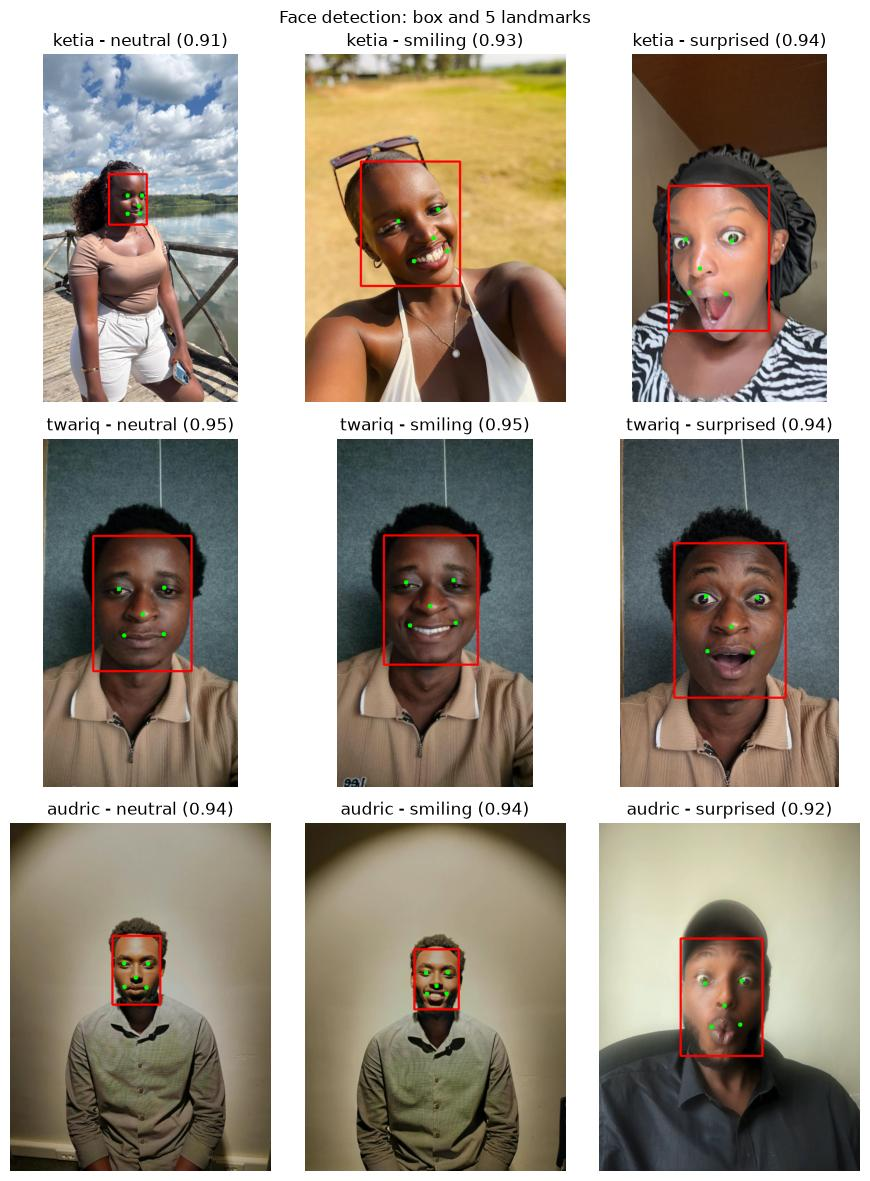

,member,expression,face_size,face_%_of_photo,confidence
0,ketia,neutral,87x116,2.8,0.911
1,ketia,smiling,228x286,13.7,0.926
2,ketia,surprised,231x333,21.5,0.936
3,twariq,neutral,226x311,19.6,0.947
4,twariq,smiling,216x297,17.9,0.952
5,twariq,surprised,256x355,22.6,0.940
6,audric,neutral,110x158,3.6,0.942
7,audric,smiling,102x138,3.0,0.940
8,audric,surprised,188x270,10.7,0.923


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(9, 12))
detections = []
for i, member in enumerate(MEMBERS):
    for j, expression in enumerate(EXPRESSIONS):
        img = load_image(f"images/raw/{member}_{expression}.jpg")
        face = detect_face(img)
        x, y, w, h = face[:4].astype(int)

        shown = img.copy()
        cv2.rectangle(shown, (x, y), (x + w, y + h), (0, 0, 255), 3)
        for k in range(5):
            cv2.circle(shown, (int(face[4 + 2 * k]), int(face[5 + 2 * k])), 5, (0, 255, 0), -1)
        axes[i, j].imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB))
        axes[i, j].set_title(f"{member} - {expression} ({face[-1]:.2f})")
        axes[i, j].axis("off")

        detections.append({"member": member, "expression": expression,
                           "face_size": f"{w}x{h}",
                           "face_%_of_photo": round(100 * face[2] * face[3] / (img.shape[0] * img.shape[1]), 1),
                           "confidence": round(float(face[-1]), 3)})
plt.suptitle("Face detection: box and 5 landmarks")
plt.tight_layout()
plt.savefig("figures/task2_02_face_detection.png", dpi=80)
plt.show()

pd.DataFrame(detections)

**Reading the detections.** YuNet found exactly one face in every photo, with confidence between 0.91 and 0.95. The hardest cases are wide shots where the face is small: `ketia_neutral` (2.8% of the frame), `audric_smiling` (3.0%) and `audric_neutral` (3.6%). All three are still found, and their face boxes (87×116 to 110×158 px) are close to the 112 px aligned crop, so little detail is lost when they are aligned.

## 3. Augmentation

Each photo gets **six augmentations**, each copying a condition the login camera will meet:

| Augmentation | How | Real-world condition it copies |
|---|---|---|
| `rotate_15` | rotate 15° about the centre, edges filled by replication | head tilted, phone held at an angle |
| `flip_horizontal` | mirror left–right | front cameras that mirror the preview |
| `grayscale` | convert to grey, keep 3 channels | grey or IR webcams, colour lost |
| `low_light` | gamma 1.8 (darkens mid-tones) | dim room, evening |
| `gaussian_blur` | 9×9 Gaussian kernel | out of focus, slight motion |
| `gaussian_noise` | add N(0, 15²) noise per pixel, fixed seed | cheap sensor, high ISO grain |

The augmentations are applied to the **whole photo, before detection**. That way the full pipeline (detect → align → describe) faces each condition, exactly as it would at login. 9 photos × (1 original + 6 augmentations) = **63 rows**, 21 per member.

In [7]:
def rotate_15(img):
    h, w = img.shape[:2]
    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), 15, 1.0)
    return cv2.warpAffine(img, matrix, (w, h), borderMode=cv2.BORDER_REPLICATE)

def flip_horizontal(img):
    return cv2.flip(img, 1)

def grayscale(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

def low_light(img, gamma=1.8):
    table = ((np.arange(256) / 255) ** gamma * 255).astype(np.uint8)
    return cv2.LUT(img, table)

def gaussian_blur(img):
    return cv2.GaussianBlur(img, (9, 9), 0)

def gaussian_noise(img, sigma=15):
    noise = rng.normal(0, sigma, img.shape)
    return np.clip(img + noise, 0, 255).astype(np.uint8)

augment = {"rotate_15": rotate_15, "flip_horizontal": flip_horizontal, "grayscale": grayscale,
           "low_light": low_light, "gaussian_blur": gaussian_blur, "gaussian_noise": gaussian_noise}

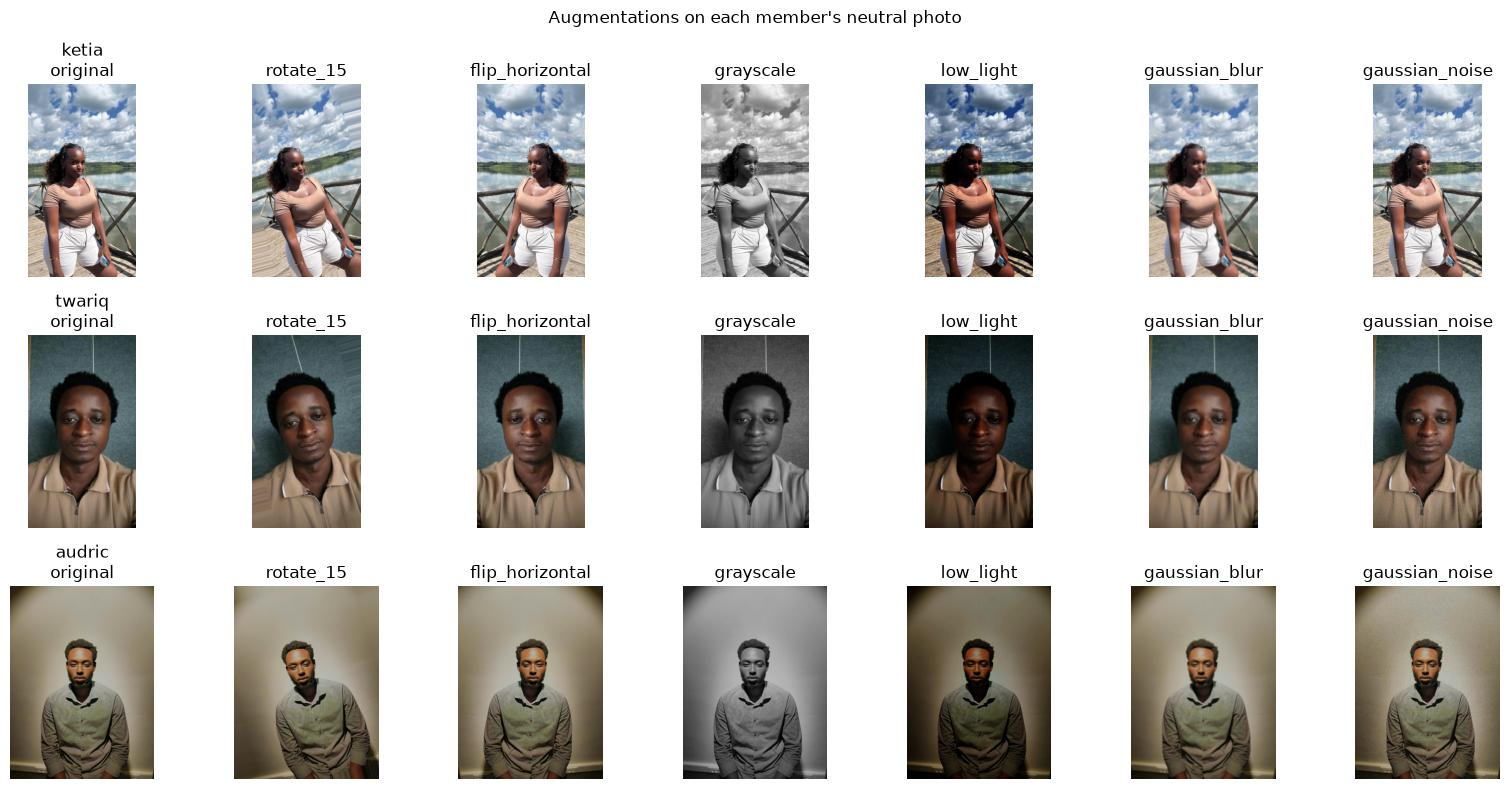

In [8]:
rng = np.random.default_rng(42)  # fixed seed so the noise is the same every run

fig, axes = plt.subplots(3, 7, figsize=(16, 8))
for i, member in enumerate(MEMBERS):
    img = load_image(f"images/raw/{member}_neutral.jpg")
    axes[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{member}\noriginal")
    for j, name in enumerate(AUGMENTATIONS, start=1):
        axes[i, j].imshow(cv2.cvtColor(augment[name](img), cv2.COLOR_BGR2RGB))
        axes[i, j].set_title(name)
    for ax in axes[i]:
        ax.axis("off")
plt.suptitle("Augmentations on each member's neutral photo")
plt.tight_layout()
plt.savefig("figures/task2_03_augmentations.png", dpi=80)
plt.show()

## 4. Feature extraction → `image_features.csv`

For every one of the 63 variants: save the augmented photo to `images/augmented/`, run detect → align → describe, save the aligned 112×112 face to `images/faces/`, and keep one row of features.

Each row also stores where it came from (`member`, `expression`, `augmentation`, `image_path`) and the detector's `face_score`. The face recognition model in Task 4 uses `member` as the label.

In [9]:
rng = np.random.default_rng(42)  # reset, so the saved noise copies are the same every run

rows = []
faces = {}
for member in MEMBERS:
    for expression in EXPRESSIONS:
        raw_path = f"images/raw/{member}_{expression}.jpg"
        img = load_image(raw_path)

        for aug in ["original"] + AUGMENTATIONS:
            image_id = f"{member}_{expression}_{aug}"
            if aug == "original":
                new_img, path = img, raw_path
            else:
                new_img = augment[aug](img)
                path = f"images/augmented/{image_id}.jpg"
                cv2.imwrite(path, new_img, [cv2.IMWRITE_JPEG_QUALITY, 92])

            face = detect_face(new_img)
            if face is None:
                print("no face found in", image_id)
                continue
            crop = recognizer.alignCrop(new_img, face)  # 112x112, eyes level
            cv2.imwrite(f"images/faces/{image_id}.png", crop)
            faces[image_id] = crop

            row = {"image_id": image_id, "member": member, "expression": expression,
                   "augmentation": aug, "image_path": path, "face_score": round(float(face[-1]), 4)}
            row.update(zip(feature_columns, get_features(crop)))
            rows.append(row)

image_features = pd.DataFrame(rows)
print("faces found in", len(image_features), "of", 9 * 7, "images")

faces found in 63 of 63 images


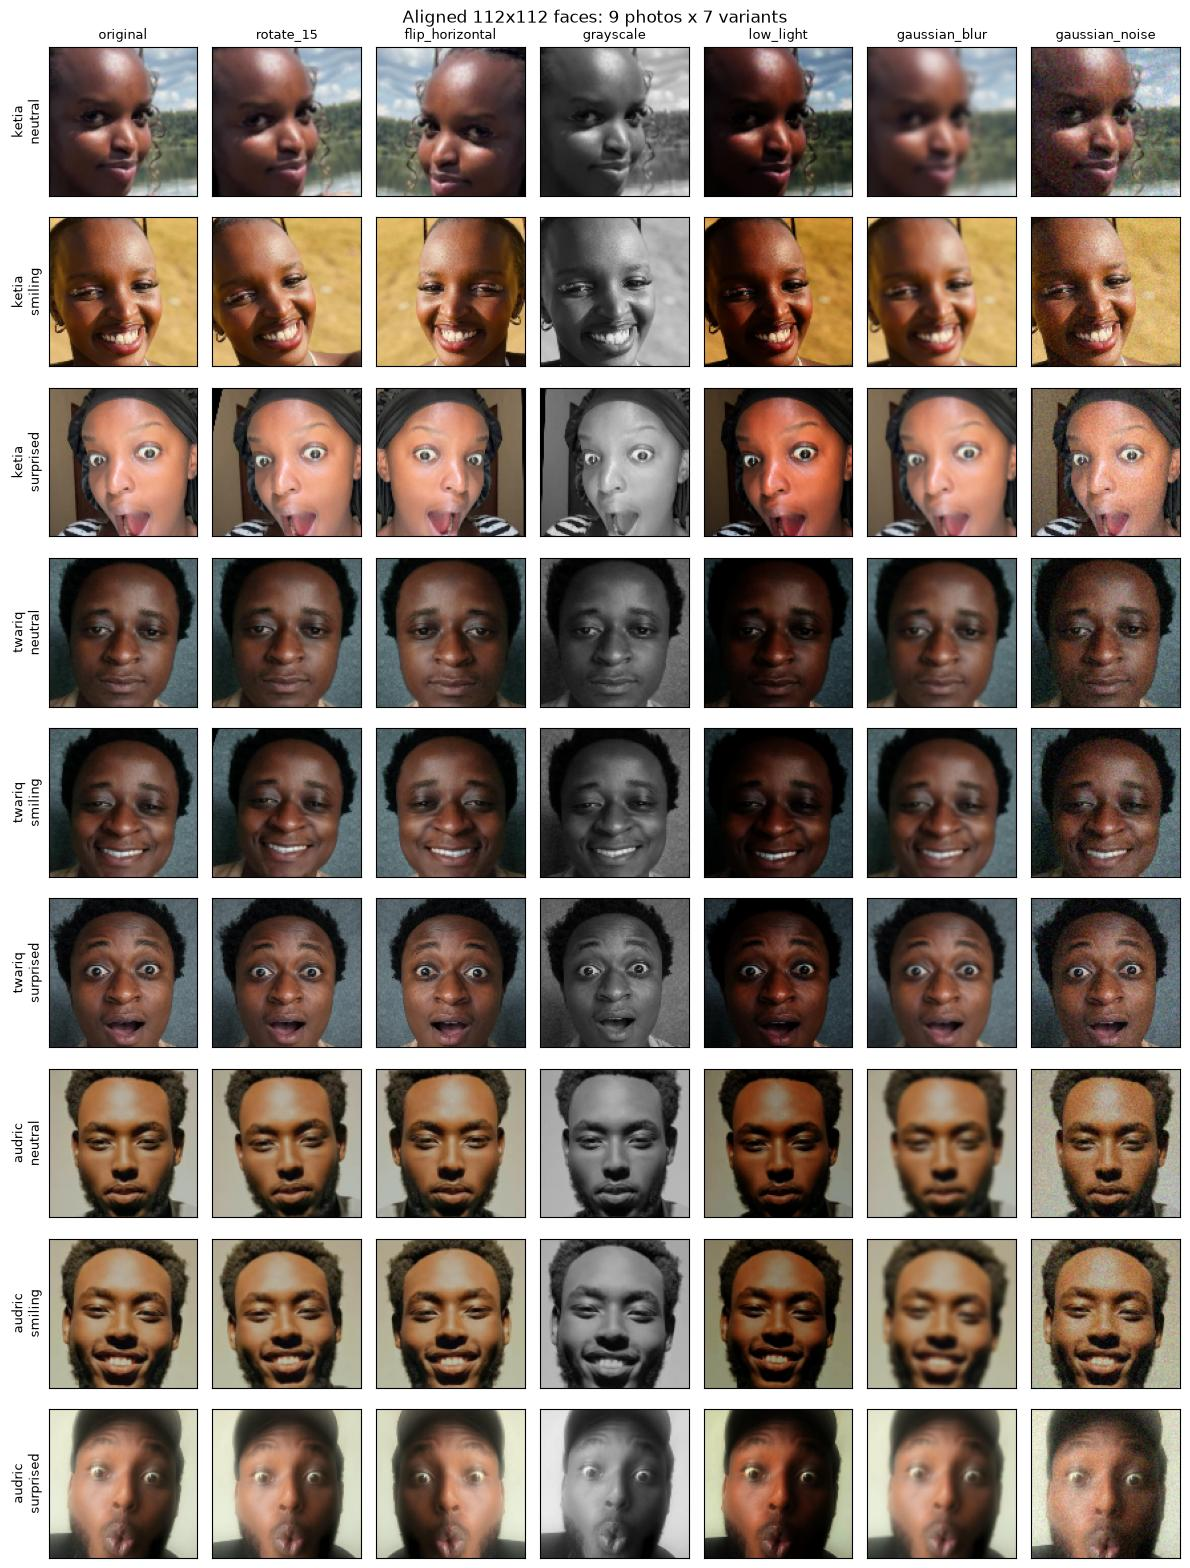

In [10]:
# what the model actually sees: the aligned face for every photo (rows) and variant (columns)
variants = ["original"] + AUGMENTATIONS
photos = [f"{m}_{e}" for m in MEMBERS for e in EXPRESSIONS]

fig, axes = plt.subplots(9, 7, figsize=(12, 16))
for i, photo in enumerate(photos):
    for j, aug in enumerate(variants):
        axes[i, j].imshow(cv2.cvtColor(faces[f"{photo}_{aug}"], cv2.COLOR_BGR2RGB))
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
        if i == 0:
            axes[i, j].set_title(aug, fontsize=9)
        if j == 0:
            axes[i, j].set_ylabel(photo.replace("_", "\n"), fontsize=9)
plt.suptitle("Aligned 112x112 faces: 9 photos x 7 variants")
plt.tight_layout()
plt.savefig("figures/task2_04_aligned_faces.png", dpi=80)
plt.show()

**Reading the aligned faces.** Alignment does its job. The `rotate_15` column looks almost the same as `original` because the landmarks are used to level the eyes again, and `flip_horizontal` mirrors the face, not the framing. The variants that really change what the embedding model sees are `grayscale`, `low_light`, `gaussian_blur` and `gaussian_noise`.

### 4.1 What the hand-crafted features look like

One aligned face broken into its colour and texture features. The LBP map labels each pixel by the pattern of its 8 neighbours (flat skin, edge, corner, spot), and the histogram counts how often each pattern appears.

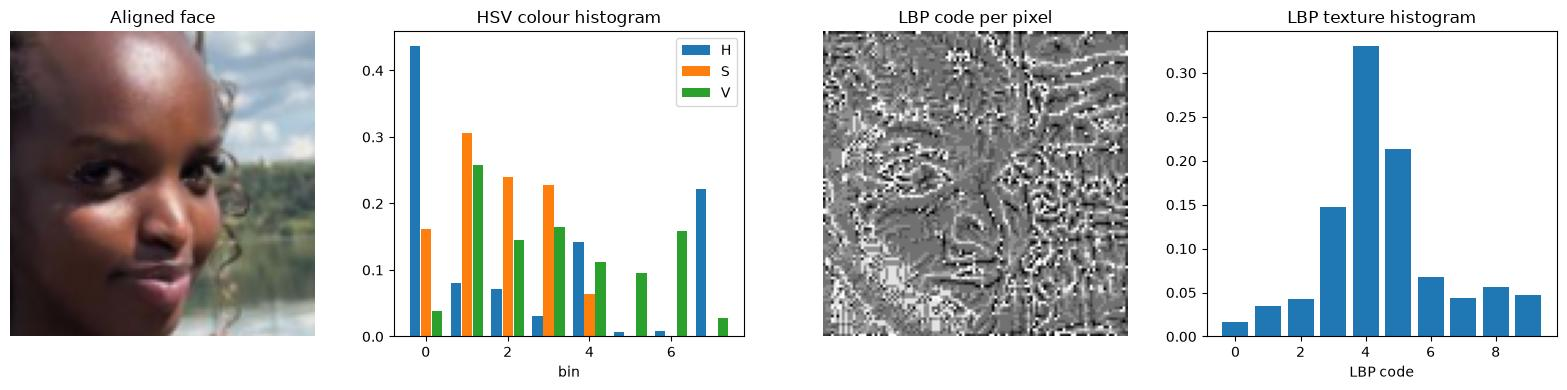

In [11]:
example = "ketia_neutral_original"
crop = faces[example]
row = image_features[image_features["image_id"] == example].iloc[0]
gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
axes[0].set_title("Aligned face")
axes[0].axis("off")

for offset, channel in enumerate(["h", "s", "v"]):
    values = [row[f"hsv_{channel}_{b}"] for b in range(8)]
    axes[1].bar(np.arange(8) + (offset - 1) * 0.27, values, width=0.25, label=channel.upper())
axes[1].set_title("HSV colour histogram")
axes[1].set_xlabel("bin")
axes[1].legend()

axes[2].imshow(local_binary_pattern(gray, 8, 1, method="uniform"), cmap="gray")
axes[2].set_title("LBP code per pixel")
axes[2].axis("off")

axes[3].bar(range(10), [row[f"lbp_{b}"] for b in range(10)])
axes[3].set_title("LBP texture histogram")
axes[3].set_xlabel("LBP code")
plt.tight_layout()
plt.savefig("figures/task2_05_handcrafted_features.png")
plt.show()

### 4.2 Save and validate `image_features.csv`

In [12]:
image_features.to_csv("features/image_features.csv", index=False)

check = pd.read_csv("features/image_features.csv")
emb_cols = [c for c in check.columns if c.startswith("emb_")]
print("shape:", check.shape)
print("missing values:", check.isnull().sum().sum())
print("duplicate image ids:", check["image_id"].duplicated().sum())
print("embedding lengths between", np.linalg.norm(check[emb_cols], axis=1).min().round(4),
      "and", np.linalg.norm(check[emb_cols], axis=1).max().round(4))
pd.crosstab(check["member"], check["augmentation"])

shape: (63, 170)
missing values: 0
duplicate image ids: 0
embedding lengths between 1.0 and 1.0


augmentation,flip_horizontal,gaussian_blur,gaussian_noise,grayscale,low_light,original,rotate_15
member,,,,,,,
audric,3,3,3,3,3,3,3
ketia,3,3,3,3,3,3,3
twariq,3,3,3,3,3,3,3


**Feature file.** 63 rows (21 per member, 9 per variant) and 170 columns: 6 metadata and 164 features. There are no missing values and no duplicate IDs. Every embedding has length 1, as it should.

In [13]:
check[["image_id", "member", "expression", "augmentation", "face_score",
       "emb_000", "emb_001", "hsv_h_0", "lbp_0", "brightness", "contrast"]].head(8)

,image_id,member,expression,augmentation,face_score,emb_000,emb_001,hsv_h_0,lbp_0,brightness,contrast
0,ketia_neutral_original,ketia,neutral,original,0.9112,-0.054707,-0.063316,0.437022,0.016422,0.389507,0.232462
1,ketia_neutral_rotate_15,ketia,neutral,rotate_15,0.9112,-0.029804,-0.004968,0.458945,0.012277,0.393296,0.230298
2,ketia_neutral_flip_horizontal,ketia,neutral,flip_horizontal,0.9168,0.057486,0.080111,0.429448,0.016024,0.400332,0.230141
3,ketia_neutral_grayscale,ketia,neutral,grayscale,0.9025,-0.044022,-0.067253,1.000000,0.015466,0.383183,0.228927
4,ketia_neutral_low_light,ketia,neutral,low_light,0.8924,-0.038985,-0.073869,0.496094,0.013951,0.231039,0.214632
5,ketia_neutral_gaussian_blur,ketia,neutral,gaussian_blur,0.9092,-0.050745,-0.046714,0.454321,0.001674,0.393434,0.220195
6,ketia_neutral_gaussian_noise,ketia,neutral,gaussian_noise,0.8838,-0.056333,-0.039296,0.375638,0.071827,0.385799,0.224331
7,ketia_smiling_original,ketia,smiling,original,0.9257,-0.089137,-0.024191,0.995456,0.042331,0.475526,0.251055


In [14]:
check[["face_score", "brightness", "contrast"]].describe().round(3)

,face_score,brightness,contrast
count,63.000,63.000,63.000
mean,0.929,0.360,0.203
std,0.016,0.108,0.052
min,0.884,0.101,0.088
25%,0.921,0.255,0.149
50%,0.936,0.393,0.218
75%,0.941,0.444,0.230
max,0.952,0.503,0.291


## 5. Do the features separate the members?

The face model in Task 4 can only be as good as these features. Three checks, run before any model exists:

1. **Similarity heatmap** of the 9 original photos: the same person should score high, different people low.
2. **Within-member vs between-member similarity** over all 63 rows, against OpenCV's published SFace threshold (0.363).
3. **PCA** of the 128-d embeddings down to 2-D: members should form separate clusters, and augmented copies should sit near their originals.

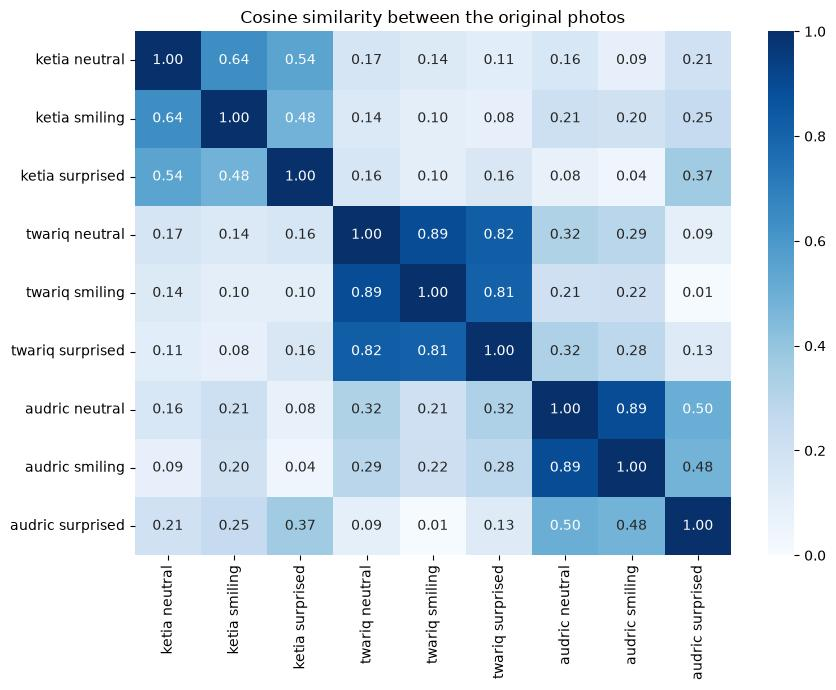

In [15]:
originals = check[check["augmentation"] == "original"]
emb = originals[emb_cols].values
sim = emb @ emb.T  # the embeddings have length 1, so this is cosine similarity
names = (originals["member"] + " " + originals["expression"]).tolist()

plt.figure(figsize=(9, 7))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=names, yticklabels=names)
plt.title("Cosine similarity between the original photos")
plt.tight_layout()
plt.savefig("figures/task2_06_similarity_heatmap.png")
plt.show()

**Reading the heatmap.** Photos of the same member score 0.48 to 0.89. Photos of different members score 0.32 at most, with one exception: `ketia_surprised` vs `audric_surprised` at 0.37. The embedding mostly encodes *who* is in the photo, not the expression or the background. Three details matter for the face model in Task 4:

- Twariq's three photos share the same place, light and camera. Neutral and smiling score 0.89 with each other; the surprised photo scores 0.81 and 0.82 against them, so its expression adds real variety.
- Audric's two wall photos score 0.89 with each other, but only 0.48 and 0.50 against the cap selfie. The selfie is a close-up with a cap and a very different expression, so this member's rows have the widest spread.
- The two surprised photos are the closest cross-member pair. Both show the same exaggerated expression (wide eyes, rounded mouth), and a strong expression pulls two different faces toward each other. Each is still closer to its own member's photos: 0.48–0.54 for `ketia_surprised`, 0.48–0.50 for `audric_surprised`.

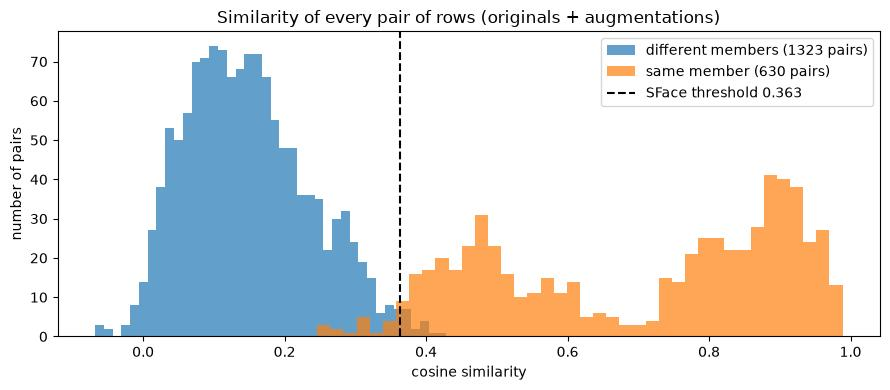

,pairs,mean,min,max,share above threshold
same member,630,0.703,0.246,0.989,0.975
different members,1323,0.149,-0.068,0.429,0.012


In [16]:
all_emb = check[emb_cols].values
sim_all = all_emb @ all_emb.T
members = check["member"].values

same, different = [], []
for i in range(len(check)):
    for j in range(i + 1, len(check)):
        if members[i] == members[j]:
            same.append(sim_all[i, j])
        else:
            different.append(sim_all[i, j])
same, different = np.array(same), np.array(different)

THRESHOLD = 0.363  # OpenCV's published same-person threshold for SFace
plt.figure(figsize=(9, 4))
plt.hist(different, bins=40, alpha=0.7, label=f"different members ({len(different)} pairs)")
plt.hist(same, bins=40, alpha=0.7, label=f"same member ({len(same)} pairs)")
plt.axvline(THRESHOLD, color="black", linestyle="--", label=f"SFace threshold {THRESHOLD}")
plt.xlabel("cosine similarity")
plt.ylabel("number of pairs")
plt.title("Similarity of every pair of rows (originals + augmentations)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/task2_07_similarity_distribution.png")
plt.show()

pd.DataFrame({
    "pairs": [len(same), len(different)],
    "mean": [same.mean(), different.mean()],
    "min": [same.min(), different.min()],
    "max": [same.max(), different.max()],
    "share above threshold": [(same > THRESHOLD).mean(), (different > THRESHOLD).mean()],
}, index=["same member", "different members"]).round(3)

**Reading the distribution.** Same-member pairs average 0.703, and 97.5% of them clear OpenCV's 0.363 threshold. Different-member pairs average 0.149. 16 of the 1,323 (1.2%) clear the threshold, the highest at 0.429. 15 of the 16 pair a `ketia_surprised` variant with an `audric_surprised` variant, and the highest of them involve a noisy or darkened copy. The 16th, just over the line at 0.369, is a flipped `twariq_surprised` copy against a blurred `audric_neutral` copy. 15 of the 16 same-member pairs below the threshold belong to Ketia, mostly smiling vs surprised (11), and 10 of the 16 involve a `gaussian_noise` copy. No two original photos of the same member fall below it.

For Task 4 this means a bare cosine threshold is not enough, because it would let the two surprised faces match each other. Compare a login face against **every** member and take the best match (the nearest-original check below gets the member right 54 times out of 54), or use the trained classifier's probability. Only then apply a threshold, to reject strangers.

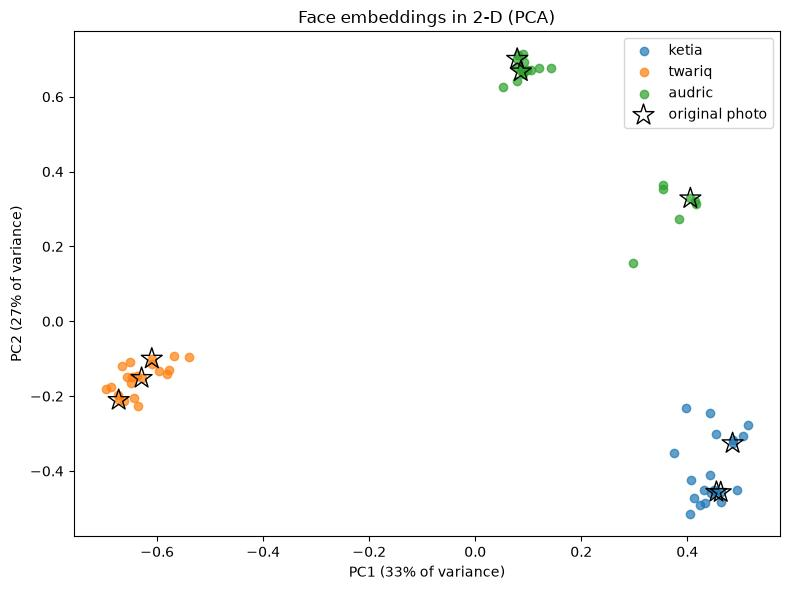

In [17]:
pca = PCA(n_components=2)
points = pca.fit_transform(all_emb)
is_original = (check["augmentation"] == "original").values

plt.figure(figsize=(8, 6))
for member in MEMBERS:
    m = members == member
    plt.scatter(points[m, 0], points[m, 1], alpha=0.7, label=member)
plt.scatter(points[is_original, 0], points[is_original, 1], marker="*", s=250,
            facecolors="none", edgecolors="black", label="original photo")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.title("Face embeddings in 2-D (PCA)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/task2_08_embedding_pca.png")
plt.show()

**Reading the PCA plot.** Two components keep 60% of the embedding variance (33% + 27%), and the three members already form three separate clusters. Twariq is the tightest cluster, because all three photos share the same place, light and camera. Audric splits into two sub-groups, the two wall photos and the cap close-up, as the heatmap showed. Augmented copies (dots) stay close to their originals (the stars): the augmentations add realistic variety without producing a face that looks like someone else.

In [18]:
# for each augmented copy: which original photo is it most similar to?
original_row = {}
for i, row in check.iterrows():
    if row["augmentation"] == "original":
        original_row[row["member"] + "_" + row["expression"]] = i

results = []
for i, row in check.iterrows():
    if row["augmentation"] == "original":
        continue
    source = row["member"] + "_" + row["expression"]
    nearest = max(original_row, key=lambda photo: sim_all[i, original_row[photo]])
    results.append({"augmentation": row["augmentation"],
                    "right_member": nearest.split("_")[0] == row["member"],
                    "own_photo": nearest == source,
                    "similarity_to_source": sim_all[i, original_row[source]]})
results = pd.DataFrame(results)

print("nearest original is the right member:", results["right_member"].sum(), "/", len(results))
print("nearest original is its own source photo:", results["own_photo"].sum(), "/", len(results))
results.groupby("augmentation")["similarity_to_source"].agg(["mean", "min"]).round(3)

nearest original is the right member: 54 / 54
nearest original is its own source photo: 54 / 54


,mean,min
augmentation,,
flip_horizontal,0.909,0.649
gaussian_blur,0.958,0.926
gaussian_noise,0.857,0.593
grayscale,0.929,0.884
low_light,0.941,0.904
rotate_15,0.918,0.594


**Nearest-original check.** All 54 augmented copies are closest to an original photo of the right member, and all 54 are closest to their own source photo. Noise moves the embedding most (mean similarity to the source 0.857, lowest 0.593); blur and low light move it least (0.958 and 0.941).

## 6. Summary and hand-off

**Delivered by this notebook**

| File | Content |
|---|---|
| `images/raw/` | 9 photos, `<member>_<expression>.jpg` |
| `images/augmented/` | 54 augmented photos, `<member>_<expression>_<augmentation>.jpg` |
| `images/faces/` | 63 aligned 112×112 faces used for features |
| `features/image_features.csv` | 63 rows × 170 columns (6 metadata + 164 features) |
| `src/image_features.py` | the same face steps as plain functions, for the CLI app |
| `figures/task2_*.png` | every figure in this notebook, for the report |

**For the face recognition model (Task 4)**: use `member` as the label and the `emb_*` columns as the main inputs. The colour, texture and tone columns can be added and compared in an ablation. Split train and test **by source photo**, not by row (for example, keep each member's `surprised` photo and its 6 copies out of training). Otherwise copies of the same photo end up on both sides of the split and inflate the score.

**For the CLI demo (Task 6)**: process a login photo exactly like the training rows:

```python
from src.image_features import features_from_path
x = features_from_path("login.jpg")   # None -> no face found -> access denied
```

For the unauthorised attempt, use a photo of someone outside the team. Match the login face against every member first, then reject it if the best similarity (or the classifier's top probability) is below the chosen threshold; the CLI then shows "Access denied". Don't use the threshold on its own: `ketia_surprised` and `audric_surprised` score 0.37 against each other (section 5).